# MROOT data analysis

I want to check what the final training data contains before interpreting model
scores. This notebook uses the committed train/validation manifests and the
image-header audit from the actual Kaggle files. It does not load holdout images.

The image audit reads headers and checks file integrity. It does not judge whether
a disease label is medically correct. The outputs below were executed from the
committed evidence during the repository update.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
REPORTS = ROOT / "reports/raw"
plt.style.use("default")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

In [2]:
train = pd.read_csv(ROOT / "data/manifests/experiment_train.csv")
validation = pd.read_csv(ROOT / "data/manifests/experiment_validation.csv")
mapping = json.loads((ROOT / "class_mapping.json").read_text())
summary = json.loads((REPORTS / "eda_summary.json").read_text())
print("Training images:", len(train))
print("Validation images:", len(validation))
print("Disease classes:", len(mapping))
print("Missing disease labels:", train.disease.isna().sum() + validation.disease.isna().sum())
print("Shared paths:", len(set(train.path) & set(validation.path)))
print("Shared detected groups:", len(set(train.duplicate_group) & set(validation.duplicate_group)))
print("Unreadable or missing image files in the source audit:", summary["unreadable_or_missing"])
assert len(train) == 6790 and len(validation) == 388
assert set(train.label) == set(validation.label) == set(range(39))
assert not set(train.duplicate_group) & set(validation.duplicate_group)

Training images: 6790
Validation images: 388
Disease classes: 39
Missing disease labels: 0
Shared paths: 0
Shared detected groups: 0
Unreadable or missing image files in the source audit: 0


## Class support

The final training set is imbalanced. Replacement sampling can balance the
class distribution seen by the optimizer, but it also repeats some examples.
The validation set has nine or ten examples per class, so a small number of
difficult photos can change class metrics substantially.

Smallest training class: berry_blotch 68
Largest training class: powdery_mildew 755
Largest/smallest support ratio: 11.1


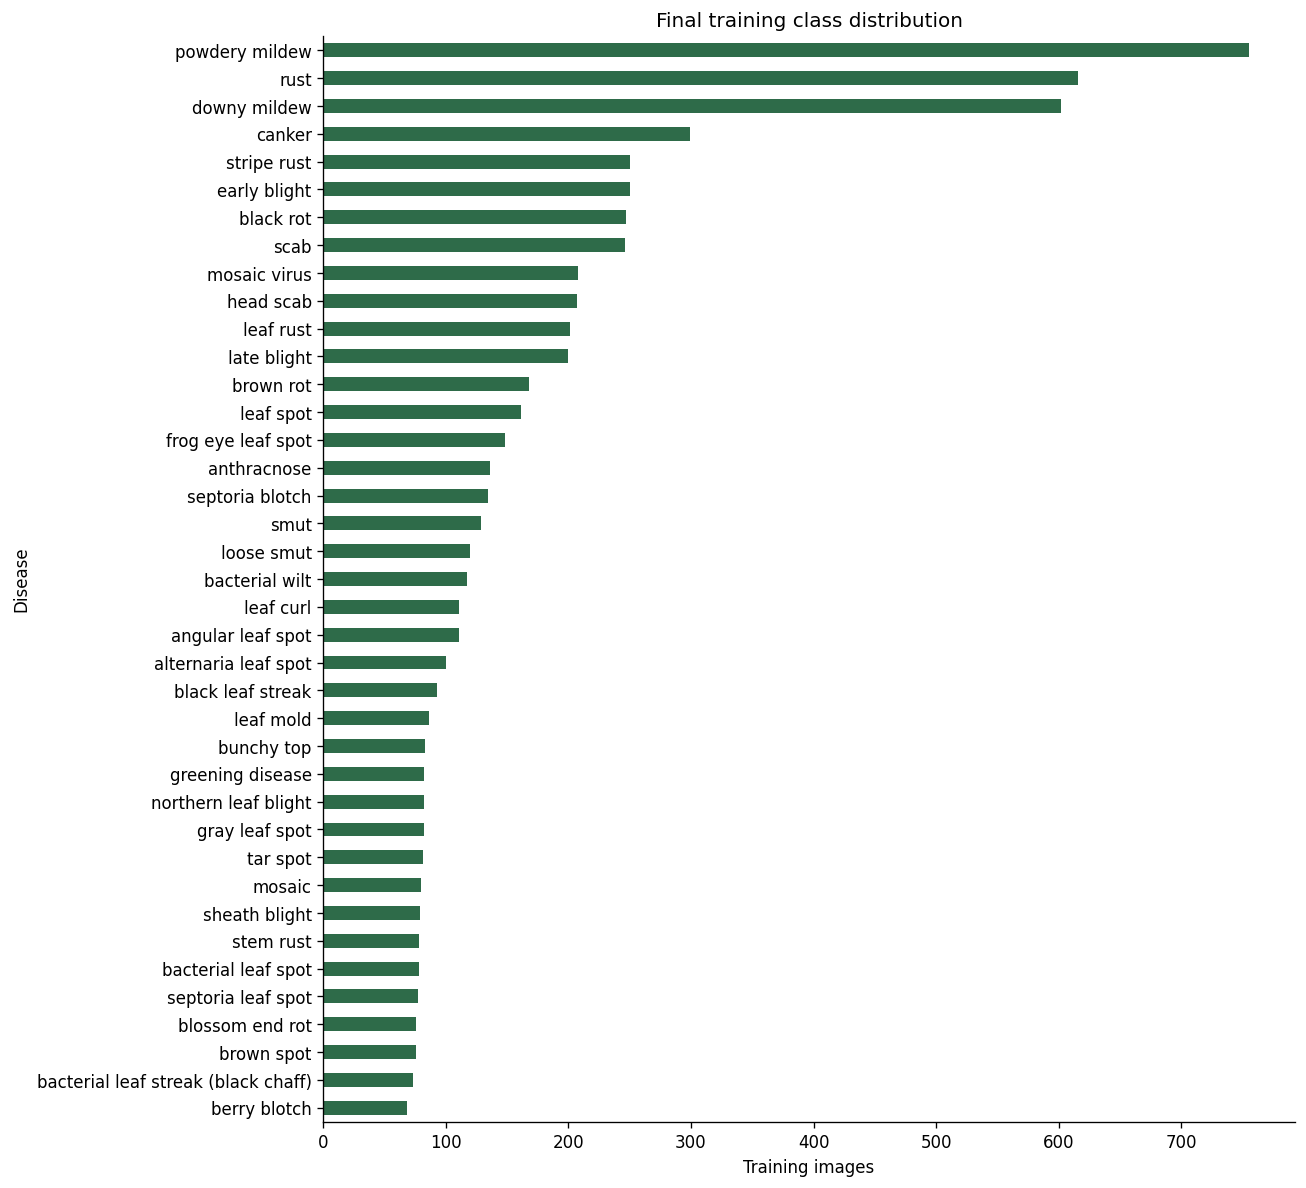

In [3]:
counts = train.groupby("disease").size().sort_values()
print("Smallest training class:", counts.index[0], int(counts.iloc[0]))
print("Largest training class:", counts.index[-1], int(counts.iloc[-1]))
print("Largest/smallest support ratio:", round(counts.iloc[-1] / counts.iloc[0], 2))
fig, ax = plt.subplots(figsize=(11, 10))
counts.rename(index=lambda value: value.replace("_", " ")).plot.barh(ax=ax, color="#2E6B49")
ax.set(xlabel="Training images", ylabel="Disease", title="Final training class distribution")
fig.tight_layout()

## Image size and shape

I resize images for the model rather than treating their original width or file
size as prediction features. The normal view uses the saved 448-pixel squash
transform. The padded view keeps the whole photograph, which helps retain
context that a crop or a stretched view may change.

            width  height  aspect_ratio  file_bytes
split                                              
train       665.5   534.0          1.33     67541.0
validation  693.0   523.5          1.33     69416.0


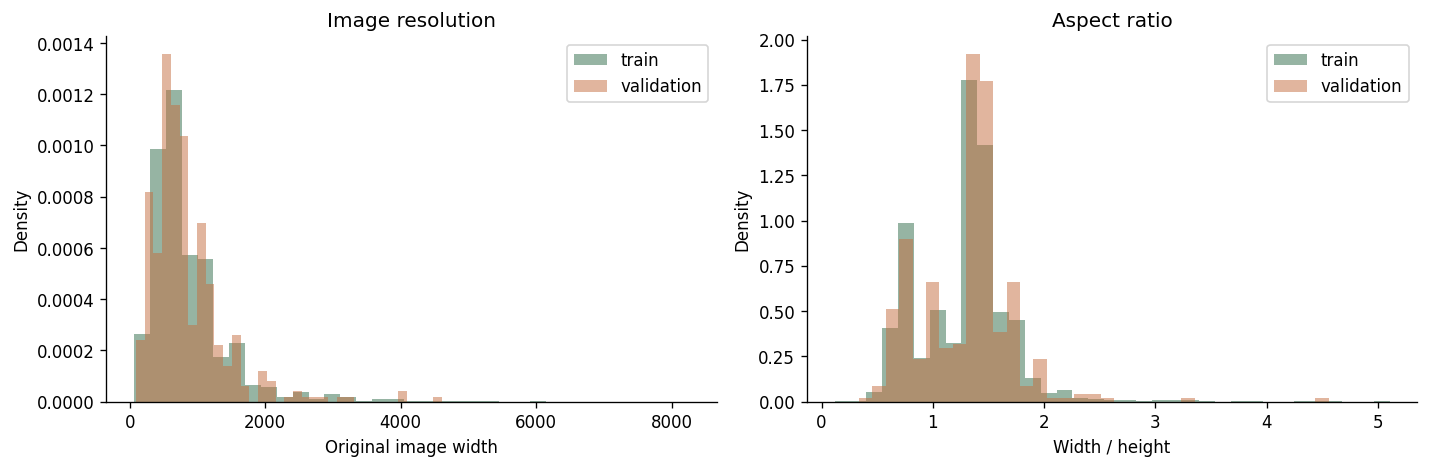

In [4]:
metadata = pd.read_csv(REPORTS / "image_metadata.csv")
print(metadata.groupby("split")[["width", "height", "aspect_ratio", "file_bytes"]].median().round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split, color in [("train", "#2E6B49"), ("validation", "#C56D3E")]:
    frame = metadata.query("split == @split")
    axes[0].hist(frame.width, bins=35, alpha=0.5, density=True, label=split, color=color)
    axes[1].hist(frame.aspect_ratio, bins=35, alpha=0.5, density=True, label=split, color=color)
axes[0].set(xlabel="Original image width", ylabel="Density", title="Image resolution")
axes[1].set(xlabel="Width / height", ylabel="Density", title="Aspect ratio")
for ax in axes:
    ax.legend()
fig.tight_layout()

## Correlations between image metadata

The rubric asks for feature correlations. This is an image model, so these
metadata correlations are descriptive checks rather than hand-engineered model
features. Width, height, and file size can be related, but that does not show
whether a disease label is correct or whether the model uses background cues.

              width  height  aspect_ratio  file_bytes
width         1.000   0.836         0.156       0.841
height        0.836   1.000        -0.344       0.861
aspect_ratio  0.156  -0.344         1.000      -0.116
file_bytes    0.841   0.861        -0.116       1.000


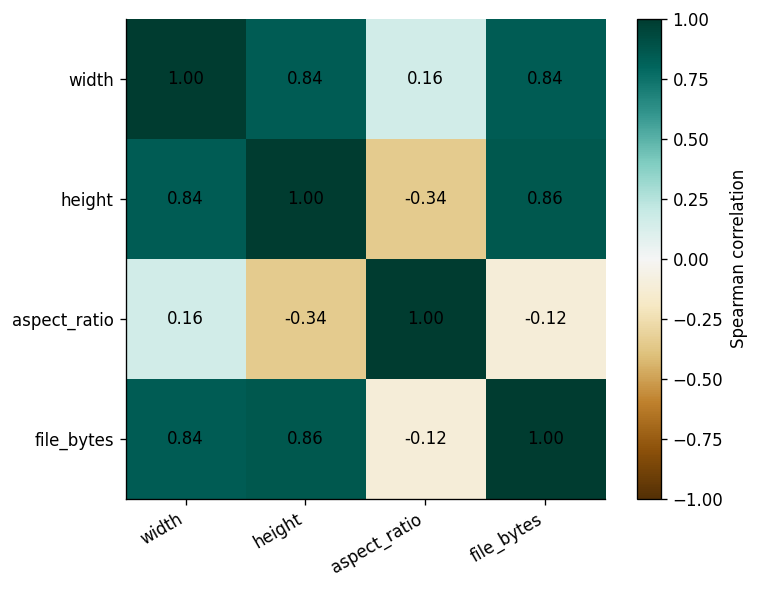

In [5]:
features = metadata[["width", "height", "aspect_ratio", "file_bytes"]]
correlations = features.corr(method="spearman")
print(correlations.round(3).to_string())
fig, ax = plt.subplots(figsize=(6.5, 5))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap="BrBG")
ax.set_xticks(range(4), correlations.columns, rotation=30, ha="right")
ax.set_yticks(range(4), correlations.index)
for row in range(4):
    for column in range(4):
        ax.text(column, row, f"{correlations.iloc[row, column]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Spearman correlation")
fig.tight_layout()

## Class support and validation AP

I checked whether small classes also had weak AP. This comparison uses the
mixed model's saved normal-view validation predictions on 388 images. It is
descriptive, and nine or ten validation examples per class are too few for a
strong causal conclusion.

                                     training_images  mixup_cutmix_normal_AP
class                                                                       
septoria_leaf_spot                                77                  0.5791
bacterial_leaf_spot                               78                  0.6417
rust                                             616                  0.8397
leaf_rust                                        201                  0.9205
bacterial_leaf_streak_(black_chaff)               73                  0.9310
sheath_blight                                     79                  0.9500
early_blight                                     250                  0.9532
brown_spot                                        76                  0.9573
Spearman support/AP correlation: 0.114


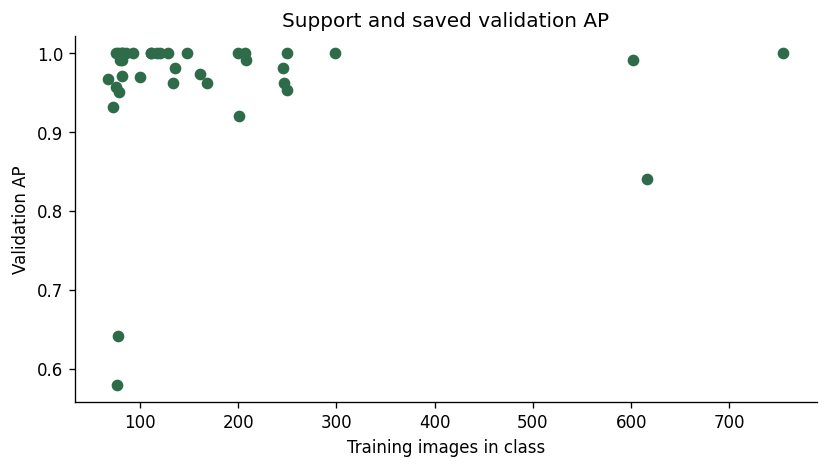

In [6]:
class_ap = pd.read_csv(REPORTS / "validation_class_comparison.csv").set_index("class")
class_ap["training_images"] = train.groupby("disease").size()
print(class_ap[["training_images", "mixup_cutmix_normal_AP"]].sort_values("mixup_cutmix_normal_AP").head(8).round(4).to_string())
print("Spearman support/AP correlation:", round(class_ap.training_images.corr(class_ap.mixup_cutmix_normal_AP, method="spearman"), 3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(class_ap.training_images, class_ap.mixup_cutmix_normal_AP, color="#2E6B49")
ax.set(xlabel="Training images in class", ylabel="Validation AP", title="Support and saved validation AP")
fig.tight_layout()

## What I changed after the audit

I used experimental manifests that quarantined 80 training rows and two
validation rows after reviewing detected image groups and one conflicting-label
group. I preserved the original images and manifests. No missing values needed
imputation in the final disease-label field, and the file audit found no unreadable
images. These checks cannot rule out undetected copies, ambiguous labels, or
domain shift. The final 368-image comparison subset belongs to the 388-image
validation set. It is not a new independent test set.